# Flipkart E-commerce Data Analysis

**Goal:** clean the data, study sales, find why revenue dropped in March 2025, and predict which customers will leave (churn).

In [37]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, roc_curve

## 1. Load the data

In [38]:
orders = pd.read_csv(r"D:\Downloads\ecommerce\data\raw\orders.csv")
products = pd.read_csv(r"D:\Downloads\ecommerce\data\raw\products.csv")
customers = pd.read_csv(r"D:\Downloads\ecommerce\data\raw\customers.csv")

print(orders.shape)
orders.head()

(100000, 14)


,order_id,order_date,customer_id,product_id,quantity,mrp,discount_pct,payment_method,order_status,channel,ship_city,ship_state,delivery_days,rating
0,OD1000075721,2025-07-22 05:35:42,C008225,P00245,2,200.0,38.0,Net Banking,Delivered,App,Hyderabad,Telangana,2.0,5.0
1,OD1000080184,2025-08-23 20:56:43,C009693,P00742,1,123610.0,2.0,UPI,Cancelled,Web,Dehradun,Uttarakhand,NaN,NaN
2,OD1000019864,2024-07-16 13:34:17,C002499,P00721,1,1450.0,2.0,Credit Card,Cancelled,App,Bhopal,Madhya Pradesh,NaN,NaN
3,OD1000076699,2025-07-29 05:27:38,C002744,P00045,1,340.0,12.0,COD,Delivered,App,Patna,Bihar,9.0,3.0
4,OD1000092991,2025-11-07 15:49:44,C004601,P00010,1,760.0,39.0,COD,Delivered,Mobile Web,Bengaluru,Karnataka,2.0,3.0


In [39]:
# check missing values and data types
orders.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 14 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   order_id        100000 non-null  object 
 1   order_date      100000 non-null  object 
 2   customer_id     100000 non-null  object 
 3   product_id      100000 non-null  object 
 4   quantity        100000 non-null  int64  
 5   mrp             100000 non-null  float64
 6   discount_pct    100000 non-null  float64
 7   payment_method  99850 non-null   object 
 8   order_status    100000 non-null  object 
 9   channel         100000 non-null  object 
 10  ship_city       100000 non-null  object 
 11  ship_state      100000 non-null  object 
 12  delivery_days   92097 non-null   float64
 13  rating          50686 non-null   float64
dtypes: float64(4), int64(1), object(9)
memory usage: 10.7+ MB


In [40]:
orders.isnull().sum()

order_id              0
order_date            0
customer_id           0
product_id            0
quantity              0
mrp                   0
discount_pct          0
payment_method      150
order_status          0
channel               0
ship_city             0
ship_state            0
delivery_days      7903
rating            49314
dtype: int64

## 2. Data cleaning

In [41]:
# 1) remove duplicate orders
dup = orders.duplicated("order_id").sum()
print("duplicates:", dup)
orders = orders.drop_duplicates("order_id")

duplicates: 400


In [42]:
# 2) fix date column (it has two different formats)
orders["order_date"] = pd.to_datetime(orders["order_date"], format="mixed")

In [43]:
# 3) fix city names (extra spaces and wrong capital letters)
wrong_city = (orders["ship_city"] != orders["ship_city"].str.strip().str.title()).sum()
print("wrong city names:", wrong_city)
orders["ship_city"] = orders["ship_city"].str.strip().str.title()

wrong city names: 300


In [44]:
# 4) missing payment method -> 'Unknown'
missing_pay = orders["payment_method"].isnull().sum()
print("missing payment:", missing_pay)
orders["payment_method"] = orders["payment_method"].fillna("Unknown")

missing payment: 150


In [45]:
# 5) discount must be between 0 and 100
wrong_disc = (orders["discount_pct"] < 0).sum() + (orders["discount_pct"] > 100).sum()
print("wrong discount:", wrong_disc)
median_disc = orders[orders["discount_pct"].between(0, 100)]["discount_pct"].median()
orders.loc[orders["discount_pct"] < 0, "discount_pct"] = median_disc
orders.loc[orders["discount_pct"] > 100, "discount_pct"] = median_disc

wrong discount: 60


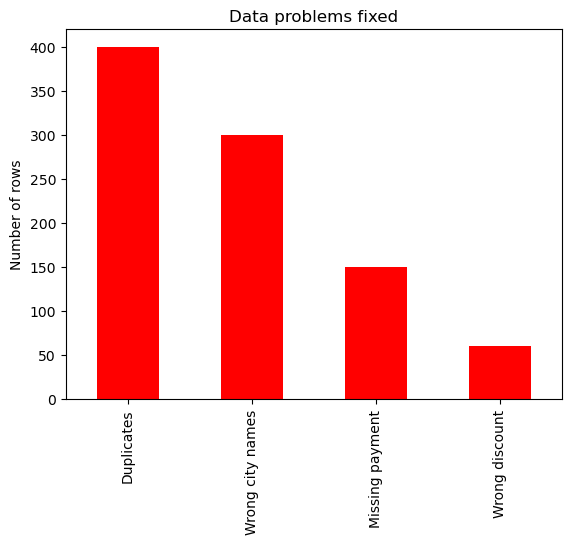

rows after cleaning: 99600


In [46]:
# graph: how many problems we fixed
problems = pd.Series({"Duplicates": dup, "Wrong city names": wrong_city,
                      "Missing payment": missing_pay, "Wrong discount": wrong_disc})
problems.plot(kind="bar", color="red")
plt.title("Data problems fixed")
plt.ylabel("Number of rows")
plt.show()
print("rows after cleaning:", len(orders))

## 3. Join the tables and make new columns

In [47]:
df = orders.merge(products, on="product_id")
df = df.merge(customers, on="customer_id")

# gmv = price after discount
df["gmv"] = df["mrp_x"] * df["quantity"] * (1 - df["discount_pct"] / 100)

# revenue is counted only for delivered orders
df["revenue"] = np.where(df["order_status"] == "Delivered", df["gmv"], 0)

df["month"] = df["order_date"].dt.to_period("M")
df.head()

,order_id,order_date,customer_id,product_id,quantity,mrp_x,discount_pct,payment_method,order_status,channel,...,seller_type,avg_rating,signup_date,home_city,age_group,plus_member,acquisition_channel,gmv,revenue,month
0,OD1000075721,2025-07-22 05:35:42,C008225,P00245,2,200.0,38.0,Net Banking,Delivered,App,...,Assured,3.9,2024-07-16,Hyderabad,25-34,No,Social,248.0,248.0,2025-07
1,OD1000080184,2025-08-23 20:56:43,C009693,P00742,1,123610.0,2.0,UPI,Cancelled,Web,...,Assured,4.7,2024-07-27,Dehradun,25-34,No,Organic,121137.8,0.0,2025-08
2,OD1000019864,2024-07-16 13:34:17,C002499,P00721,1,1450.0,2.0,Credit Card,Cancelled,App,...,Marketplace,4.2,2024-02-18,Bhopal,35-44,No,Referral,1421.0,0.0,2024-07
3,OD1000076699,2025-07-29 05:27:38,C002744,P00045,1,340.0,12.0,COD,Delivered,App,...,Assured,4.5,2025-04-05,Patna,25-34,No,Organic,299.2,299.2,2025-07
4,OD1000092991,2025-11-07 15:49:44,C004601,P00010,1,760.0,39.0,COD,Delivered,Mobile Web,...,Marketplace,3.9,2024-01-27,Bengaluru,18-24,No,Organic,463.6,463.6,2025-11


## 4. Sales analysis

In [48]:
# monthly numbers
monthly = df.groupby("month")["revenue"].sum().to_frame("revenue")
monthly["orders"] = df.groupby("month")["order_id"].count()
monthly["delivered_orders"] = df[df["order_status"] == "Delivered"].groupby("month")["order_id"].count()
monthly["aov"] = monthly["revenue"] / monthly["delivered_orders"]     # average order value
monthly["cancel_rate"] = df[df["order_status"] == "Cancelled"].groupby("month")["order_id"].count() / monthly["orders"] * 100
monthly

,revenue,orders,delivered_orders,aov,cancel_rate
month,,,,,
2024-01,14491109.16,2489,2058,7041.355277,7.754118
2024-02,15556068.13,2327,1935,8039.311695,8.250967
2024-03,20774655.13,2997,2466,8424.434359,8.274942
2024-04,19929706.39,3030,2510,7940.122068,8.382838
2024-05,22914787.83,3360,2803,8175.093767,7.738095
2024-06,22021472.60,3535,2928,7520.994740,8.260255
2024-07,24424737.34,4057,3333,7328.154017,8.380577
2024-08,25853543.13,3999,3302,7829.661760,8.877219
2024-09,28094144.01,4141,3430,8190.712539,8.210577


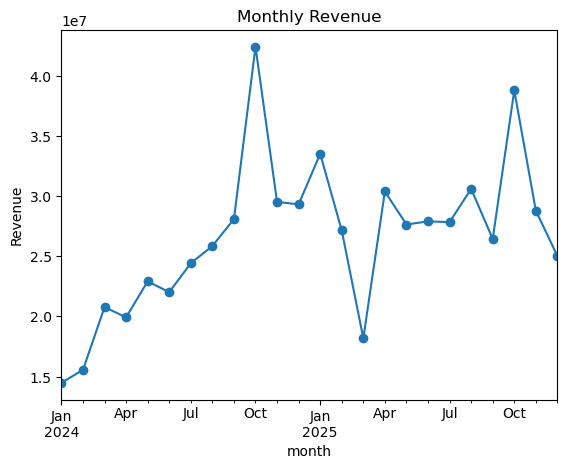

In [49]:
# Graph 1: monthly revenue
monthly["revenue"].plot(marker="o")
plt.title("Monthly Revenue")
plt.ylabel("Revenue")
plt.show()

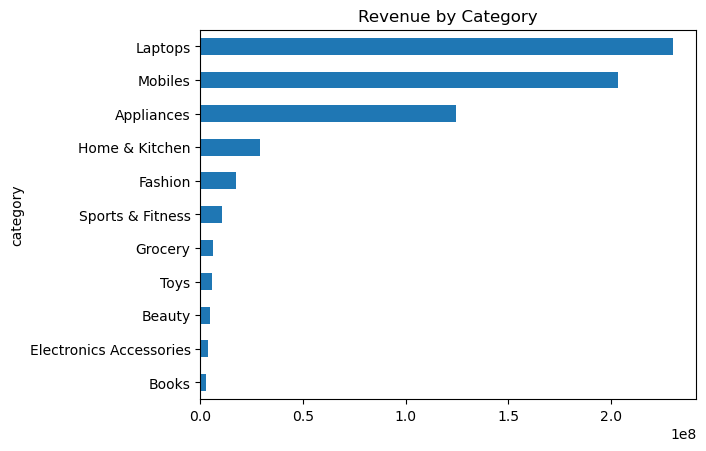

In [50]:
# Graph 2: revenue by category
cat_rev = df.groupby("category")["revenue"].sum().sort_values()
cat_rev.plot(kind="barh")
plt.title("Revenue by Category")
plt.show()

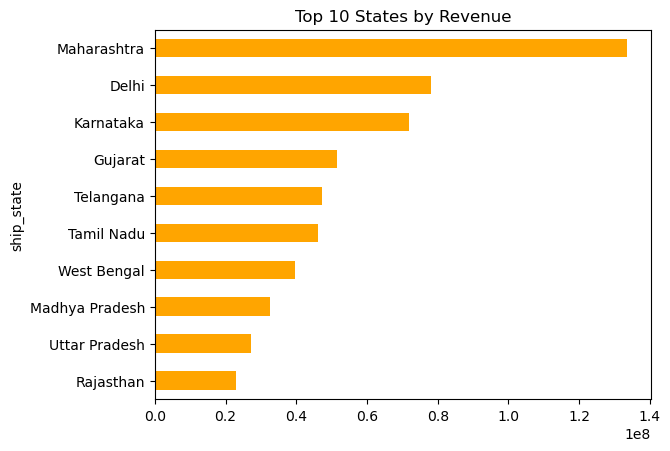

In [51]:
# Graph 3: top 10 states
state_rev = df.groupby("ship_state")["revenue"].sum().sort_values().tail(10)
state_rev.plot(kind="barh", color="orange")
plt.title("Top 10 States by Revenue")
plt.show()

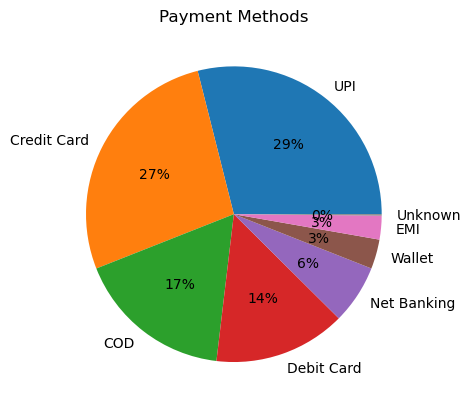

In [52]:
# Graph 4: payment method share
pay = df["payment_method"].value_counts()
pay.plot(kind="pie", autopct="%1.0f%%")
plt.title("Payment Methods")
plt.ylabel("")
plt.show()

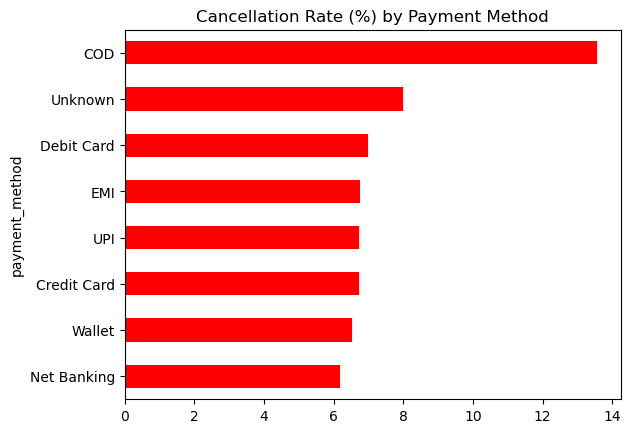

In [53]:
# Graph 5: cancel rate by payment method
total = df.groupby("payment_method")["order_id"].count()
cancelled = df[df["order_status"] == "Cancelled"].groupby("payment_method")["order_id"].count()
(cancelled / total * 100).sort_values().plot(kind="barh", color="red")
plt.title("Cancellation Rate (%) by Payment Method")
plt.show()

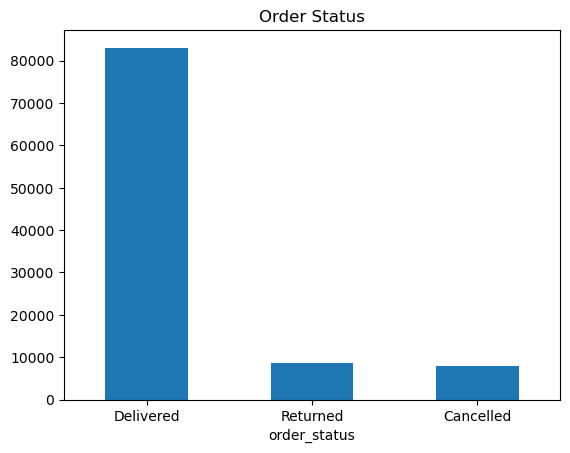

In [54]:
# Graph 6: order status
df["order_status"].value_counts().plot(kind="bar")
plt.title("Order Status")
plt.xticks(rotation=0)
plt.show()

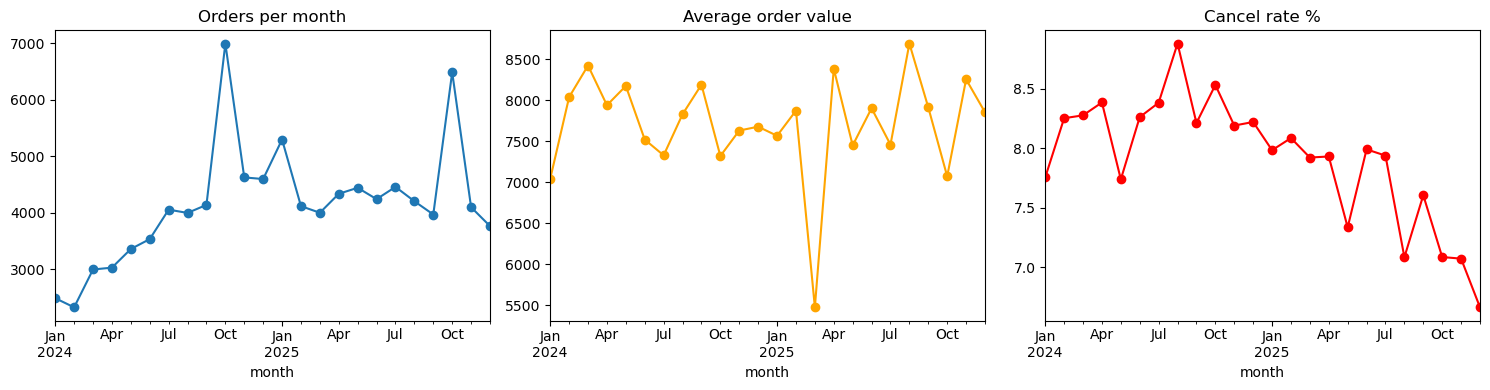

In [55]:
# Graph 7: orders, AOV and cancel rate by month
plt.figure(figsize=(15, 4))

plt.subplot(1, 3, 1)
monthly["orders"].plot(marker="o")
plt.title("Orders per month")

plt.subplot(1, 3, 2)
monthly["aov"].plot(marker="o", color="orange")
plt.title("Average order value")

plt.subplot(1, 3, 3)
monthly["cancel_rate"].plot(marker="o", color="red")
plt.title("Cancel rate %")

plt.tight_layout()
plt.show()

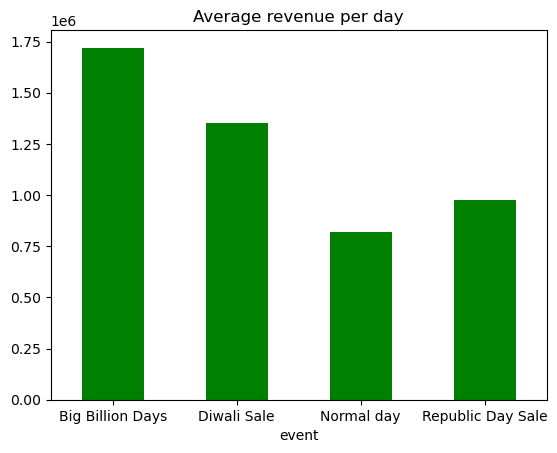

In [56]:
# Graph 8: festive sale effect (average revenue per day)
df["date"] = df["order_date"].dt.date
daily = df.groupby("date")["revenue"].sum().reset_index()
daily["date"] = pd.to_datetime(daily["date"])
daily["md"] = daily["date"].dt.strftime("%m-%d")

daily["event"] = "Normal day"
daily.loc[(daily["md"] >= "01-19") & (daily["md"] <= "01-26"), "event"] = "Republic Day Sale"
daily.loc[(daily["md"] >= "10-01") & (daily["md"] <= "10-10"), "event"] = "Big Billion Days"
daily.loc[(daily["md"] >= "10-20") & (daily["md"] <= "11-05"), "event"] = "Diwali Sale"

daily.groupby("event")["revenue"].mean().plot(kind="bar", color="green")
plt.title("Average revenue per day")
plt.xticks(rotation=0)
plt.show()

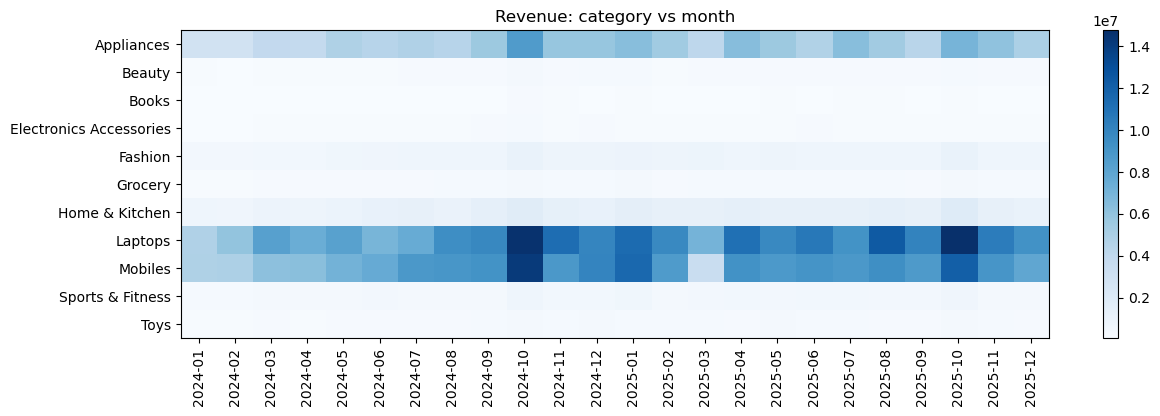

In [57]:
# Graph 9: heatmap of category vs month
table = df.pivot_table(index="category", columns="month", values="revenue", aggfunc="sum")
plt.figure(figsize=(14, 4))
plt.imshow(table, aspect="auto", cmap="Blues")
plt.xticks(range(len(table.columns)), table.columns.astype(str), rotation=90)
plt.yticks(range(len(table.index)), table.index)
plt.colorbar()
plt.title("Revenue: category vs month")
plt.show()

## 5. Why did revenue fall in March 2025?

In [58]:
feb = pd.Period("2025-02")
mar = pd.Period("2025-03")

change = (monthly.loc[mar, "revenue"] / monthly.loc[feb, "revenue"] - 1) * 100
print("Revenue change in March vs Feb:", round(change, 1), "%")

Revenue change in March vs Feb: -33.0 %


In [59]:
# Revenue = delivered orders x average order value
# so the fall is either because of fewer orders or lower order value

order_effect = (monthly.loc[mar, "delivered_orders"] - monthly.loc[feb, "delivered_orders"]) * monthly.loc[feb, "aov"]
aov_effect = (monthly.loc[mar, "aov"] - monthly.loc[feb, "aov"]) * monthly.loc[mar, "delivered_orders"]

print("Effect of fewer orders:", round(order_effect))
print("Effect of lower order value:", round(aov_effect))

Effect of fewer orders: -992125
Effect of lower order value: -7976078


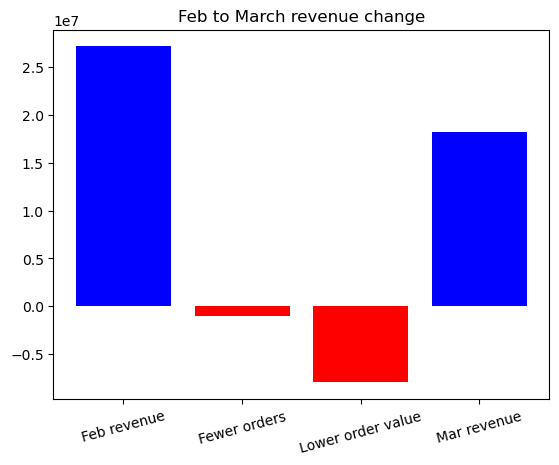

In [60]:
# Graph 10: bridge from Feb to Mar revenue
labels = ["Feb revenue", "Fewer orders", "Lower order value", "Mar revenue"]
values = [monthly.loc[feb, "revenue"], order_effect, aov_effect, monthly.loc[mar, "revenue"]]
colors = ["blue", "red", "red", "blue"]

plt.bar(labels, values, color=colors)
plt.title("Feb to March revenue change")
plt.xticks(rotation=15)
plt.show()

In [61]:
# which category caused the fall?
cat_month = df[df["month"].isin([feb, mar])].pivot_table(index="category", columns="month", values="revenue", aggfunc="sum")
cat_month["change"] = cat_month[mar] - cat_month[feb]
cat_month["change_pct"] = cat_month["change"] / cat_month[feb] * 100
cat_month = cat_month.sort_values("change")
cat_month.round(0)

month,2025-02,2025-03,change,change_pct
category,,,,
Mobiles,8648019.0,3495137.0,-5152882.0,-60.0
Laptops,9719305.0,7045868.0,-2673438.0,-28.0
Appliances,5428003.0,4107082.0,-1320922.0,-24.0
Toys,290893.0,256075.0,-34818.0,-12.0
Books,112707.0,110124.0,-2583.0,-2.0
Beauty,181450.0,190988.0,9537.0,5.0
Electronics Accessories,147155.0,171605.0,24450.0,17.0
Home & Kitchen,1231562.0,1267586.0,36024.0,3.0
Grocery,227117.0,265012.0,37895.0,17.0


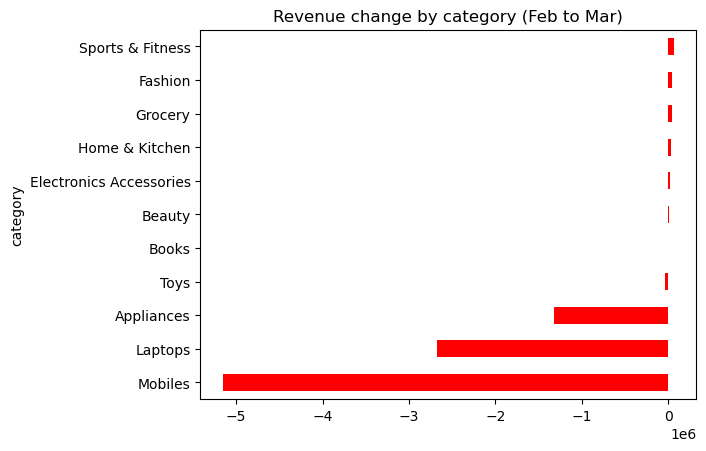

In [62]:
# Graph 11: change by category
cat_month["change"].plot(kind="barh", color="red")
plt.title("Revenue change by category (Feb to Mar)")
plt.show()

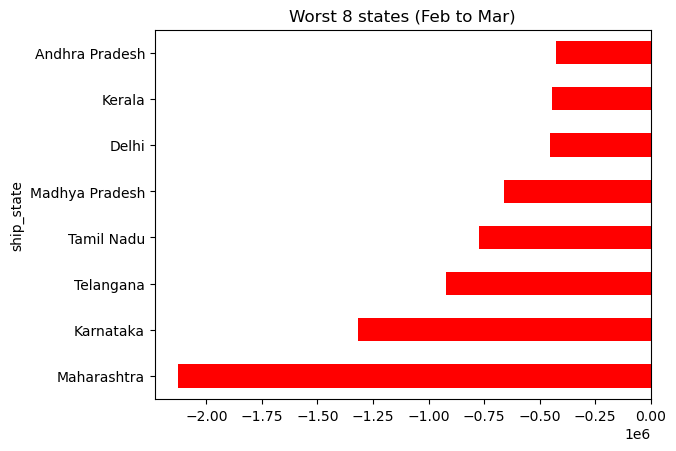

In [63]:
# which state caused the fall?
state_month = df[df["month"].isin([feb, mar])].pivot_table(index="ship_state", columns="month", values="revenue", aggfunc="sum")
state_month["change"] = state_month[mar] - state_month[feb]
state_month = state_month.sort_values("change")

# Graph 12: worst 8 states
state_month["change"].head(8).plot(kind="barh", color="red")
plt.title("Worst 8 states (Feb to Mar)")
plt.show()

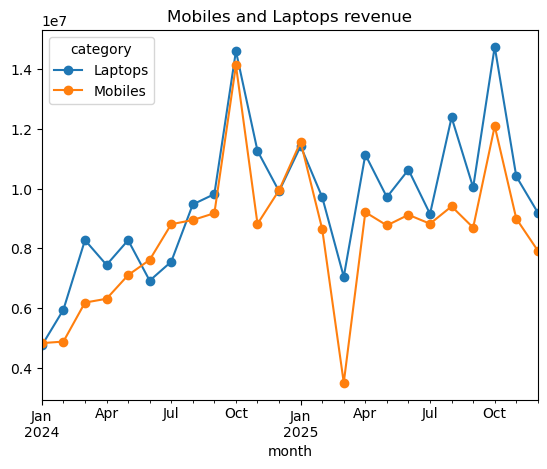

In [64]:
# Graph 13: Mobiles and Laptops over time
two = df[df["category"].isin(["Mobiles", "Laptops"])]
two.pivot_table(index="month", columns="category", values="revenue", aggfunc="sum").plot(marker="o")
plt.title("Mobiles and Laptops revenue")
plt.show()

**Conclusion:** March revenue fell about 33%. Most of the fall is because of lower order value (fewer expensive items sold), mainly in **Mobiles (-60%)** and **Laptops (-28%)**. Maharashtra and Karnataka were hit the most.

## 6. Churn prediction
A customer is *churned* if they do not order in the next 3 months.

In [65]:
snapshot = pd.Timestamp("2025-09-30")
end_date = pd.Timestamp("2025-12-31")

# use only the past data to make customer features
past = df[df["order_date"] <= snapshot]

cust = pd.DataFrame()
cust["last_order"] = past.groupby("customer_id")["order_date"].max()
cust["recency"] = (snapshot - cust["last_order"]).dt.days
cust["frequency"] = past.groupby("customer_id")["order_id"].count()
cust["spend"] = past.groupby("customer_id")["revenue"].sum()
cust["avg_delivery_days"] = past.groupby("customer_id")["delivery_days"].mean()
cust["avg_discount"] = past.groupby("customer_id")["discount_pct"].mean()
cust["cancel_rate"] = past[past["order_status"] == "Cancelled"].groupby("customer_id")["order_id"].count() / cust["frequency"]
cust = cust.drop(columns="last_order").fillna(0)

# only active customers (ordered in last 180 days)
cust = cust[cust["recency"] <= 180]
print("active customers:", len(cust))

active customers: 9316


In [66]:
# label: did the customer order in the next 3 months?
future = df[(df["order_date"] > snapshot) & (df["order_date"] <= end_date)]
future_customers = future["customer_id"].unique()

cust["churned"] = 1
cust.loc[cust.index.isin(future_customers), "churned"] = 0

print("churn rate:", round(cust["churned"].mean() * 100, 1), "%")

churn rate: 41.8 %


In [67]:
# train / test split and model
X = cust.drop(columns="churned")
y = cust["churned"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

model = RandomForestClassifier(n_estimators=200, max_depth=6, random_state=42)
model.fit(X_train, y_train)

prob = model.predict_proba(X_test)[:, 1]
print("Model AUC:", round(roc_auc_score(y_test, prob), 3))
print("Only recency AUC:", round(roc_auc_score(y_test, X_test["recency"]), 3))

Model AUC: 0.724
Only recency AUC: 0.677


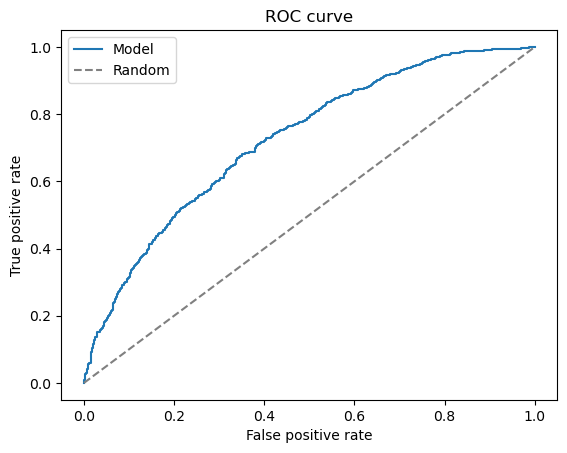

In [68]:
# Graph 14: ROC curve
fpr, tpr, _ = roc_curve(y_test, prob)
plt.plot(fpr, tpr, label="Model")
plt.plot([0, 1], [0, 1], "--", color="grey", label="Random")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("ROC curve")
plt.legend()
plt.show()

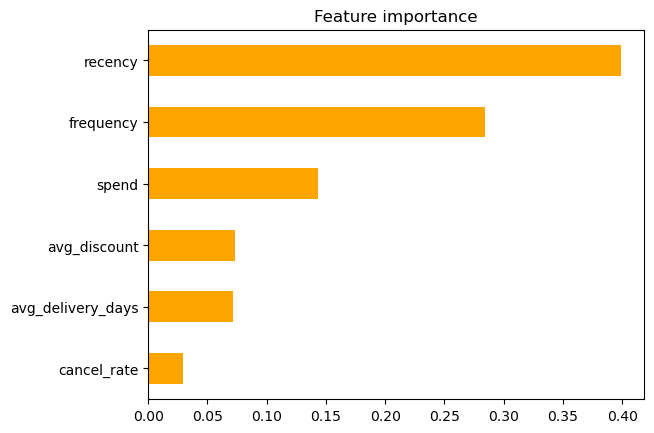

In [69]:
# Graph 15: which features matter most
imp = pd.Series(model.feature_importances_, index=X.columns).sort_values()
imp.plot(kind="barh", color="orange")
plt.title("Feature importance")
plt.show()

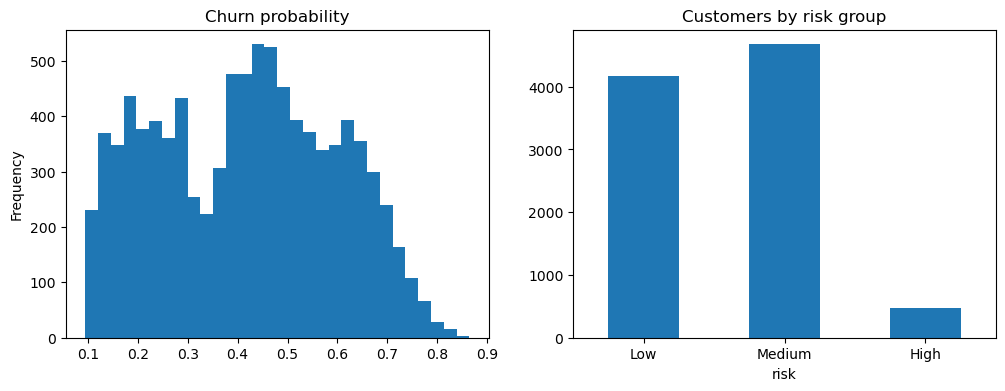

In [70]:
# Graph 16: churn probability and risk groups
cust["churn_prob"] = model.predict_proba(X)[:, 1]
cust["risk"] = pd.cut(cust["churn_prob"], [0, 0.4, 0.7, 1], labels=["Low", "Medium", "High"])

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
cust["churn_prob"].plot(kind="hist", bins=30)
plt.title("Churn probability")

plt.subplot(1, 2, 2)
cust["risk"].value_counts().reindex(["Low", "Medium", "High"]).plot(kind="bar")
plt.title("Customers by risk group")
plt.xticks(rotation=0)
plt.show()

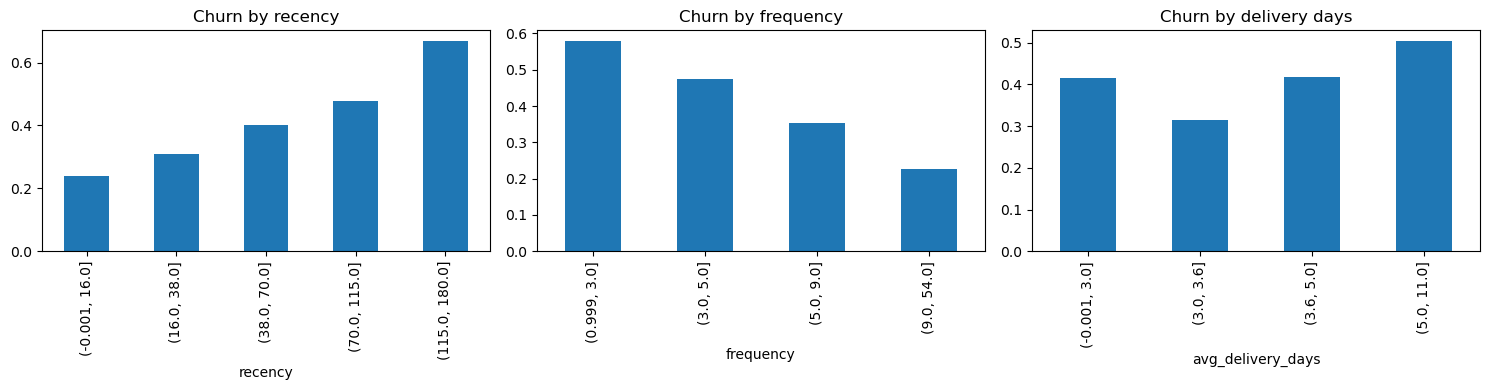

In [72]:
# Graph 17: churn % by customer behaviour
plt.figure(figsize=(15, 4))

plt.subplot(1, 3, 1)
cust.groupby(pd.qcut(cust["recency"], 5, duplicates="drop"), observed=True)["churned"].mean().plot(kind="bar")
plt.title("Churn by recency")

plt.subplot(1, 3, 2)
cust.groupby(pd.qcut(cust["frequency"], 4, duplicates="drop"), observed=True)["churned"].mean().plot(kind="bar")
plt.title("Churn by frequency")

plt.subplot(1, 3, 3)
cust.groupby(pd.qcut(cust["avg_delivery_days"], 4, duplicates="drop"), observed=True)["churned"].mean().plot(kind="bar")
plt.title("Churn by delivery days")

plt.tight_layout()
plt.show()

**Conclusion:** customers who have not ordered for a long time and who order rarely are most likely to churn. Send them offers first.

In [73]:
# Simple business recommendations based on the analysis

recommendations = []

if change < 0:
    recommendations.append([
        "Revenue Decline",
        f"Revenue fell {abs(change):.1f}% in March vs February.",
        "Improve AOV using bundles, cross-selling and targeted offers."
    ])

recommendations.append([
    "Mobiles & Laptops",
    "These categories showed a major revenue decline.",
    "Use targeted promotions and check pricing, inventory and demand."
])

worst_states = ", ".join(state_month.head(2).index.astype(str))

recommendations.append([
    "Regional Decline",
    f"Highest revenue decline was seen in {worst_states}.",
    "Investigate local pricing, delivery, inventory and competition."
])

high_risk = (cust["risk"] == "High").sum()

recommendations.append([
    "Customer Churn",
    f"{high_risk:,} customers are in the High churn-risk group.",
    "Target them first with personalized offers and retention campaigns."
])

recommendations.append([
    "Cancellation",
    "Cancellation rate is being tracked by month and payment method.",
    "Investigate high-cancellation segments and reduce avoidable cancellations."
])

recommendation_df = pd.DataFrame(
    recommendations,
    columns=["Area", "Finding", "Business Recommendation"]
)

recommendation_df

,Area,Finding,Business Recommendation
0,Revenue Decline,Revenue fell 33.0% in March vs February.,"Improve AOV using bundles, cross-selling and t..."
1,Mobiles & Laptops,These categories showed a major revenue decline.,"Use targeted promotions and check pricing, inv..."
2,Regional Decline,Highest revenue decline was seen in Maharashtr...,"Investigate local pricing, delivery, inventory..."
3,Customer Churn,480 customers are in the High churn-risk group.,Target them first with personalized offers and...
4,Cancellation,Cancellation rate is being tracked by month an...,Investigate high-cancellation segments and red...
